# Structured Food Data Extraction with Gemma 3

Hey there! In this notebook, we'll fine-tune a small language model (Gemma 3 270M) to extract structured food and drink items from raw text. We'll be using the `mrdbourke/FoodExtract-1k` dataset from Hugging Face and the `trl` library's SFTTrainer for supervised fine-tuning.

Key steps we'll cover:
1. Load the base model and tokenizer.
2. Build an inference pipeline to test baseline performance.
3. Format the dataset into conversational prompts.
4. Fine-tune the model using SFT.
5. Build a quick Gradio demo and push it to the Hugging Face Hub.

In [ ]:
!pip install trl

In [72]:
import transformers
import trl
import datasets

## Load Model
Loading the base Gemma 3 270M model and its tokenizer into memory.

In [73]:
MODEL_NAME = "google/gemma-3-270m-it"

In [74]:
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print(f"[INFO] Using device: {DEVICE}")

# Load the model and tokenizer
from transformers import AutoTokenizer, AutoModelForCausalLM

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype = 'auto',
    device_map = "auto",
    attn_implementation = 'eager'
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print(f"[INFO] Model on device: {model.device}")
print(f"[INFO] Model using dtype: {model.dtype}")

[INFO] Using device: cuda


Loading weights:   0%|          | 0/236 [00:00<?, ?it/s]

[INFO] Model on device: cuda:0
[INFO] Model using dtype: torch.bfloat16


In [75]:
model

Gemma3ForCausalLM(
  (model): Gemma3TextModel(
    (embed_tokens): Gemma3TextScaledWordEmbedding(262144, 640, padding_idx=0)
    (layers): ModuleList(
      (0-17): 18 x Gemma3DecoderLayer(
        (self_attn): Gemma3Attention(
          (q_proj): Linear(in_features=640, out_features=1024, bias=False)
          (k_proj): Linear(in_features=640, out_features=256, bias=False)
          (v_proj): Linear(in_features=640, out_features=256, bias=False)
          (o_proj): Linear(in_features=1024, out_features=640, bias=False)
          (q_norm): Gemma3RMSNorm((256,), eps=1e-06)
          (k_norm): Gemma3RMSNorm((256,), eps=1e-06)
        )
        (mlp): Gemma3MLP(
          (gate_proj): Linear(in_features=640, out_features=2048, bias=False)
          (up_proj): Linear(in_features=640, out_features=2048, bias=False)
          (down_proj): Linear(in_features=2048, out_features=640, bias=False)
          (act_fn): GELUTanh()
        )
        (input_layernorm): Gemma3RMSNorm((640,), eps=1e-06)

In [76]:
## Test tokenizer

text_tokenized_tensors = tokenizer("My name is Feroz", return_tensors = "pt").to(DEVICE)

In [77]:
text_tokenized_tensors

{'input_ids': tensor([[     2,   4754,   1463,    563,    633,   2304, 236802]],
       device='cuda:0'), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1]], device='cuda:0')}

In [78]:
output = model(**text_tokenized_tensors)

In [79]:
output[0]

tensor([[[ -8.3125,  -0.2383,  -1.5469,  ...,  -9.1250,  -9.1250,  -9.0625],
         [ -9.0625,  -2.1562,  -1.4297,  ...,  -9.1250,  -9.1875,  -9.1875],
         [-10.7500,   1.4922,  -6.1875,  ..., -10.8750, -10.9375, -10.8750],
         ...,
         [-20.8750,  -2.0781, -12.1250,  ..., -22.1250, -22.2500, -22.1250],
         [-17.0000,   8.3750,  -4.9062,  ..., -15.6875, -15.6875, -15.6250],
         [-10.5000,   6.3125,  -3.4219,  ...,  -9.0625,  -9.1250,  -9.0625]]],
       device='cuda:0', dtype=torch.bfloat16, grad_fn=<UnsafeViewBackward0>)

## Load Dataset
Pulling the `mrdbourke/FoodExtract-1k` dataset from Hugging Face and exploring a random sample.

In [80]:
from datasets import load_dataset


dataset = load_dataset("mrdbourke/FoodExtract-1k")

print(f"[INFO] Number of samples in the dataset: {len(dataset['train'])}")

[INFO] Number of samples in the dataset: 1420


In [81]:
import random

def get_random_idx(dataset):
  """returns a random integer index based on the number of samples"""
  random_idx = random.randint(0,len(dataset)-1)
  return random_idx


In [82]:
random_idx = get_random_idx(dataset['train'])
random_sample = dataset['train'][random_idx]
random_sample

{'sequence': 'In this image, there is a close-up of a robust, rectangular bar of chocolate wrapped in predominantly blue packaging. The brand name, "Tony’s Chocolonely," is boldly displayed in the iconic red font, while the word "Chocolonely" appears in white beneath it. A striking yellow band encircles one side of the chocolate bar, proclaiming “70% dark chocolate” in red writing, indicating the rich cocoa content.\n\nPositioned towards the left, a prominent yellow circle features an image of an orange chain link being pulled apart, symbolizing the brand’s dedication to fair trade and ethical practices. Surrounding the chain link graphic, the text reads, "We make chocolate 100%," though the remaining verbiage is partly obscured.\n\nWith its high cocoa content, this bar likely offers an intense, slightly bitter flavor profile synonymous with dark chocolate, suitable both for cooking and direct consumption. Tony’s thick, substantial bar encapsulates their commitment to quality and ethic

In [83]:
# Expected Input
print(random_sample['sequence'])

In this image, there is a close-up of a robust, rectangular bar of chocolate wrapped in predominantly blue packaging. The brand name, "Tony’s Chocolonely," is boldly displayed in the iconic red font, while the word "Chocolonely" appears in white beneath it. A striking yellow band encircles one side of the chocolate bar, proclaiming “70% dark chocolate” in red writing, indicating the rich cocoa content.

Positioned towards the left, a prominent yellow circle features an image of an orange chain link being pulled apart, symbolizing the brand’s dedication to fair trade and ethical practices. Surrounding the chain link graphic, the text reads, "We make chocolate 100%," though the remaining verbiage is partly obscured.

With its high cocoa content, this bar likely offers an intense, slightly bitter flavor profile synonymous with dark chocolate, suitable both for cooking and direct consumption. Tony’s thick, substantial bar encapsulates their commitment to quality and ethical chocolate produ

In [84]:
# Expected Output
print(random_sample['gpt-oss-120b-label-condensed'])

food_or_drink: 1
tags: fa, fp, fi
foods: bar of chocolate, Tony’s Chocolonely, 70% dark chocolate, dark chocolate
drinks:


### Format Dataset
We need to convert the raw dataset into conversational prompts that the training model will accept.

In [85]:
def sample_to_conversation(sample):
  return {
      "messages": [
          {"role": "user", "content": sample['sequence']},
          {"role": "assistant", "content": sample['gpt-oss-120b-label-condensed']}
      ]
  }

In [86]:
sample_to_conversation(random_sample)['messages']

[{'role': 'user',
  'content': 'In this image, there is a close-up of a robust, rectangular bar of chocolate wrapped in predominantly blue packaging. The brand name, "Tony’s Chocolonely," is boldly displayed in the iconic red font, while the word "Chocolonely" appears in white beneath it. A striking yellow band encircles one side of the chocolate bar, proclaiming “70% dark chocolate” in red writing, indicating the rich cocoa content.\n\nPositioned towards the left, a prominent yellow circle features an image of an orange chain link being pulled apart, symbolizing the brand’s dedication to fair trade and ethical practices. Surrounding the chain link graphic, the text reads, "We make chocolate 100%," though the remaining verbiage is partly obscured.\n\nWith its high cocoa content, this bar likely offers an intense, slightly bitter flavor profile synonymous with dark chocolate, suitable both for cooking and direct consumption. Tony’s thick, substantial bar encapsulates their commitment to

In [87]:
# Map sample_to_conversation function to dataset
dataset = dataset.map(sample_to_conversation, batched = False)

# Train test split
dataset = dataset['train'].train_test_split(test_size = 0.2, shuffle = False, seed = 42)

# Print a sample
random_idx = get_random_idx(dataset['train'])
print(f"[INFO] Random formatted sample: ")
print(dataset['train'][random_idx]['messages'][0])
print(dataset['train'][random_idx]['messages'][1])

[INFO] Random formatted sample: 
{'content': "The image showcases a delectable chocolate pie adorned with a tantalizing array of crushed candies and confections. Atop the pie, a medley of ingredients creates a visual feast, featuring a mix of peanut and chocolate clusters, broken pretzel bits, and generous chunks of caramel. Pieces of Reese's Peanut Butter Cups are scattered across the pie, adding to the indulgent toppings. A rich fudge drizzle cascades over the surface and sides of the pie, creating a luscious, glossy finish, with some areas oozing slightly over the exposed pie crust edges.\n\nThe pie rests upon a clear plastic cutting mat, which itself is placed on a white-textured countertop that hints at a cozy kitchenette setting. In the background, several chairs encircle what appears to be a dining table, suggesting a gathering where this sumptuous chocolate pie will soon be served. The anticipation of slicing into this generously topped dessert and sharing it among friends or f

In [88]:
dataset

DatasetDict({
    train: Dataset({
        features: ['sequence', 'image_url', 'class_label', 'source', 'char_len', 'word_count', 'syn_or_real', 'uuid', 'gpt-oss-120b-label', 'gpt-oss-120b-label-condensed', 'target_food_names_to_use', 'caption_detail_level', 'num_foods', 'target_image_point_of_view', 'messages'],
        num_rows: 1136
    })
    test: Dataset({
        features: ['sequence', 'image_url', 'class_label', 'source', 'char_len', 'word_count', 'syn_or_real', 'uuid', 'gpt-oss-120b-label', 'gpt-oss-120b-label-condensed', 'target_food_names_to_use', 'caption_detail_level', 'num_foods', 'target_image_point_of_view', 'messages'],
        num_rows: 284
    })
})

In [89]:
dataset['train'][random_idx]['messages'][0]

{'content': "The image showcases a delectable chocolate pie adorned with a tantalizing array of crushed candies and confections. Atop the pie, a medley of ingredients creates a visual feast, featuring a mix of peanut and chocolate clusters, broken pretzel bits, and generous chunks of caramel. Pieces of Reese's Peanut Butter Cups are scattered across the pie, adding to the indulgent toppings. A rich fudge drizzle cascades over the surface and sides of the pie, creating a luscious, glossy finish, with some areas oozing slightly over the exposed pie crust edges.\n\nThe pie rests upon a clear plastic cutting mat, which itself is placed on a white-textured countertop that hints at a cozy kitchenette setting. In the background, several chairs encircle what appears to be a dining table, suggesting a gathering where this sumptuous chocolate pie will soon be served. The anticipation of slicing into this generously topped dessert and sharing it among friends or family completes the inviting and 

In [90]:
## Try the model without fine-tuning using Pipeline

from transformers import pipeline

pipe = pipeline('text-generation',
                model = model,
                tokenizer = tokenizer)

# Chat templates require a list of message dicts with 'role' and 'content'
messages = [
    {"role": "user", "content": "Write a poem on Space Needle?"},


]

input_prompt = pipe.tokenizer.apply_chat_template(messages,   # replace with messages -- expects a list of dictionary
                                                  tokenize = False,
                                                  add_generation_prompt = True)

input_prompt

'<bos><start_of_turn>user\nWrite a poem on Space Needle?<end_of_turn>\n<start_of_turn>model\n'

In [91]:
# Generate text using the pipeline

outputs = pipe(
    input_prompt,
    max_new_tokens = 200,
    do_sample = True,
    temperature = 0.7
)

print(outputs[0]['generated_text'])

<bos><start_of_turn>user
Write a poem on Space Needle?<end_of_turn>
<start_of_turn>model
A titan's gaze, a silent grace,
Across the velvet, vast and wide,
A sculpted form, a timeless dream,
Where dreams take flight and softly gleam.
A dizzying height, a grand display,
Of wonder and light so bright,
A place where souls find solace and play,
A timeless sphere, a boundless sight.



In [92]:
print(outputs[0]['generated_text'][len(input_prompt):])

A titan's gaze, a silent grace,
Across the velvet, vast and wide,
A sculpted form, a timeless dream,
Where dreams take flight and softly gleam.
A dizzying height, a grand display,
Of wonder and light so bright,
A place where souls find solace and play,
A timeless sphere, a boundless sight.



## Try the model on one of the sequences
Testing the base model on a dataset sample to see its default, unstructured response.

In [93]:
random_idx = get_random_idx(dataset['train'])
random_train_sample = dataset['train'][random_idx]


# Apply chat template

input_prompt = pipe.tokenizer.apply_chat_template(
    conversation = random_train_sample['messages'][:1],
    tokenize = False,
    add_generation_prompt = True)

print(f"[INFO] Input Prompt: {input_prompt}")

# Generate baseline response -- which doesn't convert given input prompt into structured output
default_output = pipe(
    input_prompt,
    max_new_tokens = 200,
    do_sample = True,
    temperature = 0.7
)

print(f"[INFO] Output Prompt: {default_output[0]['generated_text'][len(input_prompt):]}")

[INFO] Input Prompt: <bos><start_of_turn>user
Home Theater Ideas with Dark Wood<end_of_turn>
<start_of_turn>model

[INFO] Output Prompt: Okay, let's explore some fantastic home theater ideas with dark wood! Here are some ideas, categorized to help you find the perfect fit for your space and preferences:

**Lighting & Atmosphere:**

*   **Dark Wood Lighting:**
    *   **Ambient Lighting:** Use light fixtures with dark wood finishes (e.g., dark gray, black, or even a dark, muted wood tone) to create a warm, inviting ambiance.
    *   **Accent Lighting:** Add small, thoughtful spotlights or uplighting to highlight specific features or create a focal point.
    *   **Dimmer Switches:** Install dimmer switches to adjust the lighting intensity and create a cozy, relaxing atmosphere.
*   **Dark Wood Furniture:**
    *   **Dining Chairs:** Opt for dark, low-profile chairs to create a sleek and modern look.
    *   **Coffee Tables:** Choose dark, heavy-wood coffee tables with a dark finish to a

## Let's try to prompt model to return structured outputs
Testing if zero-shot prompting with instructions can force the base model to return the specific format.

In [94]:
# Prompt Instruction

prompt_instruction = """Given the following input text from an image caption, extract food and drink items to a structured format. If there are no food or drink items, return an empty. Do not code it up. Just return structured outputs as exemplified below.

Return in the following format:
food_or_drink: total number of items
tags: [fi, di]
foods: [item 1, item 2....]
drinks: [item 1, item 2....]


For example,

Input: Traeger Sweet & Heat BBQ Sauce-Traeger-The Stove Yard

Output: 'food_or_drink: 1\ntags: fi\nfoods: Traeger Sweet & Heat BBQ Sauce\ndrinks:

Example 2,

Input: 'Nutrition Facts Label for 100% Organic Popcorn: Serving size 3 Tbsp (39g), about 17 servings per container. Calories: 110. Total Fat: 1.5g (2% DV), Saturated Fat: 0g, Trans Fat: 0g. Cholesterol: 0mg (0% DV), Sodium: 10mg (0% DV). Total Carbohydrate: 27g (9% DV), Dietary Fiber: 7g (28% DV), Total Sugars: 1g, Added Sugars: 0g (0% DV). Protein: 4g. Vitamins: Vitamin A (0% DV), Vitamin C (0% DV), Calcium (0% DV), Iron (4% DV). Ingredients: 100% Organic popcorn. Produced in a facility that processes soy and wheat. Manufactured by Bluegrass Cavern LLC, Hopkinsville, KY 42240. Certified Organic by KY Dept of Agriculture.

Output: 'food_or_drink: 1\ntags: np, il, fi, fp\nfoods: popcorn\ndrinks:

Target Input text: <target_input_text>
"""

def update_input_message_content(input):
  original_content = input['messages'][:1][0]['content']
  new_content = prompt_instruction.replace("<target_input_text>", original_content)

  return [{
      "content": new_content,
      "role": "user"
  }]

In [95]:
print(update_input_message_content(random_train_sample))

[{'content': "Given the following input text from an image caption, extract food and drink items to a structured format. If there are no food or drink items, return an empty. Do not code it up. Just return structured outputs as exemplified below.\n\nReturn in the following format:\nfood_or_drink: total number of items\ntags: [fi, di]\nfoods: [item 1, item 2....]\ndrinks: [item 1, item 2....]\n\n\nFor example,\n\nInput: Traeger Sweet & Heat BBQ Sauce-Traeger-The Stove Yard\n\nOutput: 'food_or_drink: 1\ntags: fi\nfoods: Traeger Sweet & Heat BBQ Sauce\ndrinks:\n\nExample 2,\n\nInput: 'Nutrition Facts Label for 100% Organic Popcorn: Serving size 3 Tbsp (39g), about 17 servings per container. Calories: 110. Total Fat: 1.5g (2% DV), Saturated Fat: 0g, Trans Fat: 0g. Cholesterol: 0mg (0% DV), Sodium: 10mg (0% DV). Total Carbohydrate: 27g (9% DV), Dietary Fiber: 7g (28% DV), Total Sugars: 1g, Added Sugars: 0g (0% DV). Protein: 4g. Vitamins: Vitamin A (0% DV), Vitamin C (0% DV), Calcium (0% DV)

In [96]:
random_idx = get_random_idx(dataset['train'])
random_train_sample = dataset['train'][random_idx]

sample_input = update_input_message_content(random_train_sample)
# Apply chat template

input_prompt = pipe.tokenizer.apply_chat_template(
    conversation = sample_input,
    tokenize = False,
    add_generation_prompt = True)

print(f"[INFO] Input Prompt: {input_prompt}")

# Generate baseline response -- which doesn't convert given input prompt into structured output
default_output = pipe(
    input_prompt,
    max_new_tokens = 900,
    do_sample = True,
    temperature = 0.7
)

print(f"[INFO] Model Output: {default_output[0]['generated_text'][len(input_prompt):]}")
print(f"\n\n[INFO] Ideal Output: \n{random_train_sample['messages'][1]['content']}")

[INFO] Input Prompt: <bos><start_of_turn>user
Given the following input text from an image caption, extract food and drink items to a structured format. If there are no food or drink items, return an empty. Do not code it up. Just return structured outputs as exemplified below.

Return in the following format:
food_or_drink: total number of items
tags: [fi, di]
foods: [item 1, item 2....]
drinks: [item 1, item 2....]


For example,

Input: Traeger Sweet & Heat BBQ Sauce-Traeger-The Stove Yard

Output: 'food_or_drink: 1
tags: fi
foods: Traeger Sweet & Heat BBQ Sauce
drinks:

Example 2,

Input: 'Nutrition Facts Label for 100% Organic Popcorn: Serving size 3 Tbsp (39g), about 17 servings per container. Calories: 110. Total Fat: 1.5g (2% DV), Saturated Fat: 0g, Trans Fat: 0g. Cholesterol: 0mg (0% DV), Sodium: 10mg (0% DV). Total Carbohydrate: 27g (9% DV), Dietary Fiber: 7g (28% DV), Total Sugars: 1g, Added Sugars: 0g (0% DV). Protein: 4g. Vitamins: Vitamin A (0% DV), Vitamin C (0% DV), Cal

In [97]:
def to_pc(s):
    return {
        "prompt":     [{"role": "user", "content": s["sequence"]}],
        "completion": [{"role": "assistant", "content": s["gpt-oss-120b-label-condensed"]}],
    }

cols = dataset["train"].column_names
dataset_pc = dataset.map(to_pc, remove_columns=cols)

In [98]:
dataset_pc['train']['prompt']

Column([[{'content': 'A mouth-watering photograph captures a delectable dish centered on a rectangular white porcelain plate, resting on a rustic wooden tabletop indoors. In the background, a wooden cutting board with a long handle subtly enhances the setting. The plate is adorned with several generously-sized, cheese-stuffed peppers that have been roasted to perfection, their blistered skins marked by charred black spots. Split down the middle, the peppers reveal a creamy white cheese filling, enriched with a blend of aromatic herbs. Once stuffed, the peppers have been closed and roasted, achieving a luscious, smoky flavor.\n\nThe dish is elegantly garnished with vibrant cherry tomato halves, freshly chopped green herbs, and delicate sprinkles of small diced red onions. A light, possibly citrus-infused dressing, hinted by a sheen of oil or lime juice, gently coats the ensemble, adding an extra layer of freshness. The meticulous presentation and vivid colors make this image not only a 

## Fine tune SLM using SFT
Prompting didn't give the desired behavior, so we proceed with fine-tuning using `SFTTrainer` on our supervised samples.

In [99]:
from trl import SFTConfig

# Parameters
torch_dtype = model.dtype
BASE_LEARNING_RATE = 1e-5
CHECKPOINT_DIR_NAME = "./checkpoint_models"

print(f"[INFO] Using dtype: {torch_dtype}")
print(f"[INFO] Using learning rate: {BASE_LEARNING_RATE}")




[INFO] Using dtype: torch.bfloat16
[INFO] Using learning rate: 1e-05


In [100]:
## STEP 1: SFT Config

sft_config = SFTConfig(
    output_dir = CHECKPOINT_DIR_NAME,
    max_length = 512,
    packing = False,
    num_train_epochs = 3,
    per_device_train_batch_size = 16,
    gradient_checkpointing = False,
    optim = 'adamw_torch_fused',
    logging_steps = 1,
    save_strategy = 'epoch',
    eval_strategy = 'epoch',
    learning_rate = BASE_LEARNING_RATE,
    fp16 = True if torch_dtype == torch.float16 else False,
    bf16 = True if torch_dtype == torch.bfloat16 else False,
    lr_scheduler_type = 'constant',
    push_to_hub = False,
    report_to = ['none']
)

sft_config

SFTConfig(output_dir='./checkpoint_models', per_device_train_batch_size=16, num_train_epochs=3, max_steps=-1, learning_rate=1e-05, lr_scheduler_type=<SchedulerType.CONSTANT: 'constant'>, lr_scheduler_kwargs=None, warmup_steps=0, optim=<OptimizerNames.ADAMW_TORCH_FUSED: 'adamw_torch_fused'>, optim_args=None, weight_decay=0.0, adam_beta1=0.9, adam_beta2=0.999, adam_epsilon=1e-08, optim_target_modules=None, gradient_accumulation_steps=1, average_tokens_across_devices=True, max_grad_norm=1.0, label_smoothing_factor=0.0, bf16=True, fp16=False, bf16_full_eval=False, fp16_full_eval=False, tf32=None, gradient_checkpointing=False, gradient_checkpointing_kwargs=None, torch_compile=False, torch_compile_backend=None, torch_compile_mode=None, use_liger_kernel=False, liger_kernel_config=None, use_cache=False, neftune_noise_alpha=None, torch_empty_cache_steps=None, auto_find_batch_size=False, logging_strategy=<IntervalStrategy.STEPS: 'steps'>, logging_steps=1, logging_first_step=False, log_on_each_no

In [101]:
## SFT Trainer

import torch
import gc
from trl import SFTTrainer

# Clear unused memory from the GPU
gc.collect()
torch.cuda.empty_cache()

# Keep the model in its native bfloat16 for stable gradients
model = model.to(torch.bfloat16)

# Configure precision strictly to bf16 (turn off fp16 to avoid numerical scaling conflicts)
sft_config.fp16 = False
sft_config.bf16 = True

# Gemma tokenizer requires a pad token
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

trainer = SFTTrainer(
    model = model,
    args = sft_config,
    train_dataset = dataset_pc['train'],
    eval_dataset = dataset_pc['test'],
    processing_class = tokenizer
)

trainer.train()

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': 2}.


Epoch,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
1,0.125242,0.110516,0.129417,0.973084,166873.000000
2,0.233021,0.092787,0.108031,0.976956,333746.000000
3,0.112599,0.085842,0.070102,0.978273,500619.000000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=213, training_loss=0.3858423263114383, metrics={'train_runtime': 49.3046, 'train_samples_per_second': 68.635, 'train_steps_per_second': 4.32, 'total_flos': 849432286187520.0, 'train_loss': 0.3858423263114383, 'epoch': 3.0})

In [102]:
# Save model
trainer.save_model()

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [103]:
batch = next(iter(trainer.get_train_dataloader()))
ids, labels = batch["input_ids"][0], batch["labels"][0]
print(tokenizer.decode(ids[labels != -100]))   # this is what the loss sees

food_or_drink: 1
tags: fi
foods: paleo snack, dried fruit bars
drinks:<end_of_turn>



In [104]:
batch = next(iter(trainer.get_train_dataloader()))
ids, labels = batch["input_ids"][0], batch["labels"][0]
print(tokenizer.decode(ids[labels != -100]))   # this is what the loss sees

food_or_drink: 1
tags: fi
foods: paleo snack, dried fruit bars
drinks:<end_of_turn>



In [105]:
tags = {'is_food_or_drink': True,
  'tags': ['fi', 'fa'],
  'food_items': ['cheese-stuffed peppers',
   'cherry tomato halves',
   'green herbs',
   'diced red onions',
   'citrus-infused dressing',
   'oil',
   'lime juice',
   'cheese'],
  'drink_items': []}


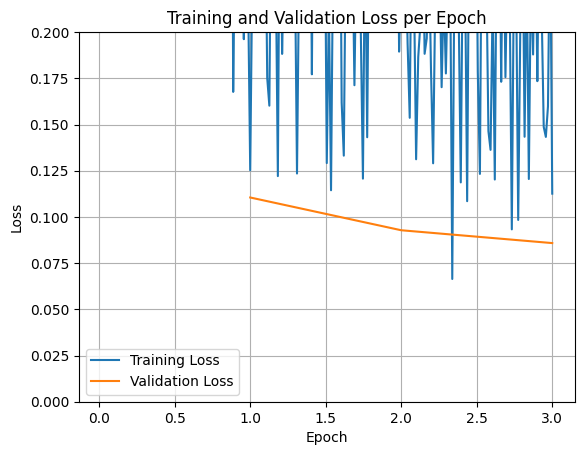

In [106]:
## Visualizing the training and validation loss

import matplotlib.pyplot as plt

# Access the log history
log_history = trainer.state.log_history

# Extract training / validation loss
train_losses = [log["loss"] for log in log_history if "loss" in log]
epoch_train = [log["epoch"] for log in log_history if "loss" in log]
eval_losses = [log["eval_loss"] for log in log_history if "eval_loss" in log]
epoch_eval = [log["epoch"] for log in log_history if "eval_loss" in log]

# Plot the training loss
plt.plot(epoch_train, train_losses, label="Training Loss")
plt.plot(epoch_eval, eval_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.ylim(0,0.2)
plt.title("Training and Validation Loss per Epoch")
plt.legend()
plt.grid(True)
plt.show()

## Load saved model and test performance
Loading our newly fine-tuned model and testing it on the unseen test dataset split.

In [107]:
from transformers import AutoTokenizer, AutoModelForCausalLM

#Load trained model
finetuned_model = AutoModelForCausalLM.from_pretrained(
    pretrained_model_name_or_path = CHECKPOINT_DIR_NAME,
    dtype = 'auto',
    device_map = 'auto',
    attn_implementation = 'eager'
)

finetuned_model_tokenizer = AutoTokenizer.from_pretrained(
    CHECKPOINT_DIR_NAME
)

Loading weights:   0%|          | 0/236 [00:00<?, ?it/s]

In [108]:
## Now we evaluate the model on test dataset

dataset['test']

Dataset({
    features: ['sequence', 'image_url', 'class_label', 'source', 'char_len', 'word_count', 'syn_or_real', 'uuid', 'gpt-oss-120b-label', 'gpt-oss-120b-label-condensed', 'target_food_names_to_use', 'caption_detail_level', 'num_foods', 'target_image_point_of_view', 'messages'],
    num_rows: 284
})

In [109]:
# Create test pipeline
loaded_model_pipeline = pipeline('text-generation',
                                 model = finetuned_model,
                                 tokenizer = finetuned_model_tokenizer)

In [110]:
random_idx = get_random_idx(dataset['test'])
random_test_sample = dataset['test'][random_idx]


# Apply chat template

input_prompt = loaded_model_pipeline.tokenizer.apply_chat_template(
    conversation = random_test_sample['messages'][:1],
    tokenize = False,
    add_generation_prompt = True)

print(f"[INFO] Input Prompt: {input_prompt}")

# Generate finetuned response
default_output = loaded_model_pipeline(
    input_prompt,
    max_new_tokens = 200,
    do_sample = True,
    temperature = 0.7
)

print(f"[INFO] Output Prompt: {default_output[0]['generated_text'][len(input_prompt):]}")
print(f"\n\n[INFO] Ground Truth: {random_test_sample['messages'][1:][0]['content']}")

[INFO] Input Prompt: <bos><start_of_turn>user
The image shows a package of "Helpful Harvest" dried vegetables. The ingredients include a variety of vegetables such as zucchini, carrots, mushrooms, onions, capsicum, and celery. The product is made from 100% vegetables and includes wonky and overly abundant produce where possible. The package notes that the ingredients and percentages may differ due to seasonal availability.

The allergens listed are milk, eggs, soy, sesame seeds, hazelnuts, pistachios, cashews, and almonds. The nutrition information indicates that the package contains 4 servings, with each serving size being 10g. The average quantities per serving are as follows:
- Energy: 125 kJ
- Protein: 1.9 g
- Gluten: 0 g (marked as gluten-free)
- Fat, total: 0.3 g
- Saturated fat: 0 g
- Carbohydrate: 3.4 g
- Sugars: 3.4 g
- Fibre: 3.4 g
- Sodium: 2.1 g

The average quantities per 100g are:
- Energy: 1250 kJ
- Protein: 18.7 g
- Fat, total: 2.8 g
- Saturated fat: 0 g
- Carbohydrate:

## Turning our model into a Demo
Wrapping the model into a simple Gradio interface to quickly test text-in, formatted-text-out.

In [111]:
import gradio as gr

from transformers import AutoModelForCausalLM, AutoTokenizer
from transformers import pipeline

MODEL_PATH = CHECKPOINT_DIR_NAME

In [112]:
## Need input message formatting

def format_input_message(input):
    return {
        "prompt":     [{"role": "user", "content": input}]
    }

input_message = "Hello, my name is Feroz and I love drinking coffee and eating bread early morning"

format_input_message(input_message)

{'prompt': [{'role': 'user',
   'content': 'Hello, my name is Feroz and I love drinking coffee and eating bread early morning'}]}

In [113]:
## Let's test this input message format is working!

output = loaded_model_pipeline(format_input_message(input_message)['prompt'])

print(f"[INFO] Input Prompt: \n{output[0]['generated_text'][0]['content']}\n\n")
print(f"[INFO] Model Output: \n{output[0]['generated_text'][1]['content']}")

[INFO] Input Prompt: 
Hello, my name is Feroz and I love drinking coffee and eating bread early morning


[INFO] Model Output: 
food_or_drink: 1
tags: fi
foods: coffee
drinks: bread



In [114]:
## The demo is simple: text in, formatted text out. We also want to check how fast is the inference

import time

def pred_on_text(input_text):
  start_time = time.time()

  formatted_input_text = format_input_message(input_text)['prompt']
  raw_output = loaded_model_pipeline(formatted_input_text)

  end_time = time.time()
  return raw_output, raw_output[0]['generated_text'][1]['content'], round(end_time-start_time,3)

In [115]:
pred_on_text("For breakfast, I had eggs, bread and a glass of orange juice and milk")

([{'generated_text': [{'role': 'user',
     'content': 'For breakfast, I had eggs, bread and a glass of orange juice and milk'},
    {'role': 'assistant',
     'content': 'food_or_drink: 1\ntags: fi\nfoods: eggs, bread, orange juice\ndrinks: milk'}]}],
 'food_or_drink: 1\ntags: fi\nfoods: eggs, bread, orange juice\ndrinks: milk',
 1.077)

In [116]:
## Gradio creates a simple prototype interface

description = """Extract Food and Drink items from text with a fine-tuned SLM

Input (str): Raw text string
Output (str): Generated text with food/not_food extraction as well as noun extracted food and drink items.

For example,

Input: "For breakfast, I had eggs, bread and a glass of orange juice and milk"
Output:
  food_or_drink: 1
  tags: fi
  foods: eggs, bread, orange juice, milk
  drinks:
"""

demo = gr.Interface(fn=pred_on_text,
                    inputs=gr.TextArea(lines=4, label="Input Text"),
                    outputs=[gr.TextArea(lines=4, label="Generated Text"),
                             gr.TextArea(lines=7, label="Raw Output"),
                             gr.Number(label="Generation Time (s)")],
                    title="Structured Extraction with a Fine-Tuned Gemma 3 270M Model",
                    description=description,
                    examples=[["Hello world! This is my first fine-tuned LLM!"],
                              ["A plate of food with grilled barramundi, salad with avocado, olives, tomatoes and Italian dressing"],
                              ["British Breakfast with baked beans, fried eggs, black pudding, sausages, bacon, mushrooms, a cup of tea and toast and fried tomatoes"],
                              ["Steak tacos"],
                              ["A photo of a dog sitting on a beach"]]
)

demo.launch(share=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

## Upload the model to Hugging Face
Pushing the fine-tuned model weights and tokenizer directly to the Hugging Face Hub.

In [ ]:
from google.colab import userdata
# Suppressing output to prevent token leakage
hf_token = userdata.get('HF_TOKEN_READ_WRITE')
print("[INFO] HF_TOKEN_READ_WRITE loaded securely.")

In [70]:
from huggingface_hub import HfApi, create_repo
from google.colab import userdata

# Retrieve your write token from Colab Secrets
hf_token = userdata.get('HF_TOKEN_READ_WRITE')

api = HfApi(token=hf_token)
repo_id = "ferozk0333/Text-Extraction-NER-FoodExtract-Gemma-3-270M-Fine-Tuned-v1"

# Create repo passing the authenticated token
create_repo(repo_id, repo_type = 'model', exist_ok = True, token=hf_token)

# Upload the entire folder containing the model files
api.upload_folder(
    folder_path = '/content/checkpoint_models',
    repo_id = repo_id,
    repo_type = 'model'
)

CommitInfo(commit_url='https://huggingface.co/ferozk0333/Text-Extraction-NER-FoodExtract-Gemma-3-270M-Fine-Tuned-v1/commit/31fce6fb80b9451e6de3219f16898e5274e431b8', commit_message='Upload folder using huggingface_hub', commit_description='', oid='31fce6fb80b9451e6de3219f16898e5274e431b8', pr_url=None, repo_url=RepoUrl('https://huggingface.co/ferozk0333/Text-Extraction-NER-FoodExtract-Gemma-3-270M-Fine-Tuned-v1', endpoint='https://huggingface.co', repo_type='model', repo_id='ferozk0333/Text-Extraction-NER-FoodExtract-Gemma-3-270M-Fine-Tuned-v1'), pr_revision=None, pr_num=None)

## Upload demo to Hugging Face
To make the Hugging Face Space demo, we need to generate an `app.py`, a `README.md`, and a `requirements.txt`.

In [119]:
!mkdir demos
!mkdir demos/FoodExtractApp

In [121]:
%%writefile demos/FoodExtractApp/app.py

## This standalone file will execute on HF Spaces -- I have just merged different code blocks into a single file
## Contains dependencies, predict function
## The file app.py will fetch model weights and tokenizer from HF repo and launch demo

# Load dependencies
import transformers, torch, gradio as gr
from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline
import time


# Load Model and Tokenizer, and Build Pipeline

MODEL_PATH = "ferozk0333/Text-Extraction-NER-FoodExtract-Gemma-3-270M-Fine-Tuned-v1"

loaded_model = AutoModelForCausalLM.from_pretrained(
    pretrained_model_name_or_path = MODEL_PATH,
    dtype = "auto",
    device_map = "auto",
    attn_implementation = "eager"
)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_PATH
)

inference_pipeline = pipeline('text-generation',
                          model = loaded_model,
                          tokenizer = tokenizer)



# Helper function
def format_input_message(input):
    return {
        "prompt":     [{"role": "user", "content": input}]
    }

# Predict function
def pred_on_text(input_text):
  start_time = time.time()

  formatted_input_text = format_input_message(input_text)['prompt']
  raw_output = inference_pipeline(formatted_input_text)

  end_time = time.time()
  return raw_output, raw_output[0]['generated_text'][1]['content'], round(end_time-start_time,3)


# Demo using Gradio

description = """Extract Food and Drink items from text with a fine-tuned SLM

Made by: Feroz Khan

Input (str): Raw text string
Output (str): Generated text with food/not_food extraction as well as noun extracted food and drink items.

For example,

Input: "For breakfast, I had eggs, bread and a glass of orange juice and milk"
Output:
  food_or_drink: 1
  tags: fi
  foods: eggs, bread, orange juice, milk
  drinks:
"""

demo = gr.Interface(fn=pred_on_text,
                    inputs=gr.TextArea(lines=4, label="Input Text"),
                    outputs=[gr.TextArea(lines=4, label="Generated Text"),
                             gr.TextArea(lines=7, label="Raw Output"),
                             gr.Number(label="Generation Time (s)")],
                    title="Structured Extraction with a Fine-Tuned Gemma 3 270M Model",
                    description=description,
                    examples=[["Hello world! This is my first fine-tuned LLM!"],
                              ["A plate of food with grilled barramundi, salad with avocado, olives, tomatoes and Italian dressing"],
                              ["British Breakfast with baked beans, fried eggs, black pudding, sausages, bacon, mushrooms, a cup of tea and toast and fried tomatoes"],
                              ["Steak tacos"],
                              ["A photo of a dog sitting on a beach"]]
)


if __name__ == '__main__':
  demo.launch(share=True)




Overwriting demos/FoodExtractApp/app.py


In [123]:
%%writefile demos/FoodExtractApp/README.md
---
title: FoodExtract Fine-tuned LLM Structured Data Extractor
emoji: 📝➡️🍟
colorFrom: green
colorTo: blue
sdk: gradio
app_file: app.py
pinned: false
license: apache-2.0
---

"""
Fine-tuned Gemma 3 270M to extract food and drink items from raw text.

Input can be any form of real text and output will be a formatted string such as the following:

```
food_or_drink: 1
tags: fi, re
foods: tacos, milk, red apple, pineapple, cherries, fried chicken, steak, mayonnaise
drinks: iced latte, matcha latte
```

The tags map to the following items:

```
tags_dict = {'np': 'nutrition_panel',
 'il': 'ingredient list',
 'me': 'menu',
 're': 'recipe',
 'fi': 'food_items',
 'di': 'drink_items',
 'fa': 'food_advertistment',
 'fp': 'food_packaging'}
```
"""

Writing demos/FoodExtractApp/README.md


In [124]:
%%writefile demos/FoodExtractApp/requirements.txt
transformers
gradio
torch

Writing demos/FoodExtractApp/requirements.txt


## Upload Demo to Hugging Face Hub
Using a template code from Hugging Face website and tailoring it to our requirements.

NOTE: Unfortunately, Hugging Face recently updated its policy. Deploying interactive Python applications using SDKs such as Gradio or Docker now requires a Hugging Face PRO account ($9/month). So, I am not putting it live. I will attach screenshots of the demo in the GitHub README.

In [ ]:
# 1. Import the required methods for uploading to the Hugging Face Hub
from huggingface_hub import (
    create_repo,
    get_full_repo_name,
    upload_file, # for uploading a single file (if necessary)
    upload_folder # for uploading multiple files (in a folder)
)
from google.colab import userdata

# 2. Define the parameters we'd like to use for the upload
LOCAL_DEMO_FOLDER_PATH_TO_UPLOAD = "demos/FoodExtractApp/"
HF_TARGET_SPACE_NAME = "FoodExtract-v1"
HF_REPO_TYPE = "space" # we're creating a Hugging Face Space
HF_SPACE_SDK = "gradio"
HF_TOKEN = userdata.get('HF_TOKEN_READ_WRITE') # Retrieve your Hugging Face write token from Colab Secrets

# 3. Create a Space repository on Hugging Face Hub
print(f"[INFO] Creating repo on Hugging Face Hub with name: {HF_TARGET_SPACE_NAME}")
create_repo(
    repo_id=HF_TARGET_SPACE_NAME,
    token=HF_TOKEN, # Set token to authorize repo creation
    repo_type=HF_REPO_TYPE,
    private=False, # set to True if you don't want your Space to be accessible to others
    space_sdk=HF_SPACE_SDK,
    exist_ok=True, # set to False if you want an error to raise if the repo_id already exists
)

# 4. Get the full repository name (e.g. {username}/{model_id} or {username}/{space_name})
full_hf_repo_name = get_full_repo_name(model_id=HF_TARGET_SPACE_NAME, token=HF_TOKEN)
print(f"[INFO] Full Hugging Face Hub repo name: {full_hf_repo_name}")

# 5. Upload our demo folder
print(f"[INFO] Uploading {LOCAL_DEMO_FOLDER_PATH_TO_UPLOAD} to repo: {full_hf_repo_name}")
folder_upload_url = upload_folder(
    repo_id=full_hf_repo_name,
    folder_path=LOCAL_DEMO_FOLDER_PATH_TO_UPLOAD,
    path_in_repo=".", # upload our folder to the root directory ("." means "base" or "root", this is the default)
    token=HF_TOKEN, # Set token to authorize folder upload
    repo_type=HF_REPO_TYPE,
    commit_message="Uploading FoodExtract demo app.py"
)
print(f"[INFO] Demo folder successfully uploaded with commit URL: {folder_upload_url}")